TEMPORAL STATISTICAL TEST

Kolom dataset:
['tgl', 'ot', 'lat', 'lon', 'depth', 'mag', 'remark', 'strike1', 'dip1', 'rake1', 'strike2', 'dip2', 'rake2']

Jumlah data awal: 92887

Periode data:
Awal : 2008-11-01 00:00:00
Akhir: 2023-01-26 00:00:00

Jumlah observasi bulanan: 171
Rata-rata gempa per bulan: 543.2
Simpangan baku: 369.61
Jumlah gempa: 92887


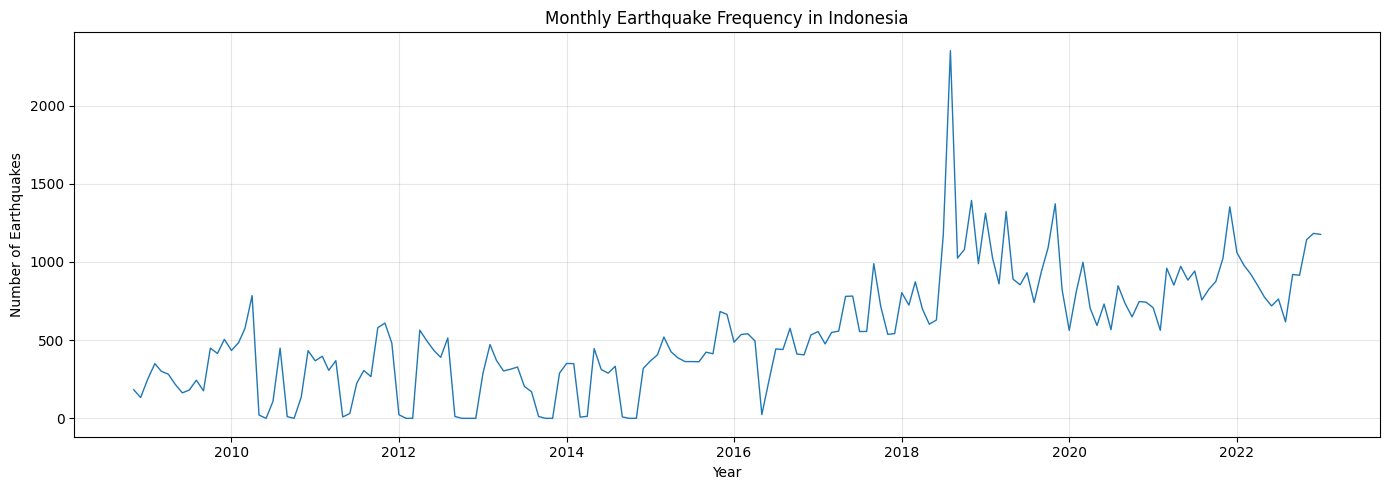


1. KENDALL TAU TEST
Kendall Tau : 0.5641
P-value     : 8.398801992995553e-28
Keputusan: H0 ditolak.
Interpretasi: tren monoton meningkat.

2. AUGMENTED DICKEY-FULLER TEST
ADF Statistic : -1.1305
P-value       : 0.7027714578669068
Used Lags     : 7
Observations  : 163

Critical Values:
1%: -3.4711
5%: -2.8794
10%: -2.5763

Keputusan: gagal menolak H0.
Interpretasi: bukti belum cukup untuk menolak unit root.

3. LJUNG-BOX TEST


/tmp/ipykernel_3686/1568113557.py:135: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(


,lb_stat,lb_pvalue
12,779.864826,3.434476e-159


Lag diuji: 12
P-value  : 3.4344763657709335e-159
Keputusan: H0 ditolak.
Interpretasi: terdapat autokorelasi temporal.

RINGKASAN TEMPORAL STATISTICAL TEST


,Statistical Test,Statistic,P-value,Significance (0.05)
0,Kendall Tau,0.5641,0.0000,Significant
1,Augmented Dickey-Fuller,-1.1305,0.7028,Not significant
2,Ljung-Box,779.8648,0.0000,Significant



Analisis selesai.


In [1]:

# ============================================================
# TEMPORAL STATISTICAL TEST PADA DATA GEMPA BUMI INDONESIA
# Tests: Kendall Tau, ADF, dan Ljung-Box
# ============================================================

# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import kendalltau
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

# ============================================================
# 2. LOAD DATASET
# ============================================================

url = (
    "https://raw.githubusercontent.com/"
    "arifadli/Paper-Penelitian/main/katalog_gempa.csv"
)

df = pd.read_csv(url)

print("=" * 60)
print("TEMPORAL STATISTICAL TEST")
print("=" * 60)

print("\nKolom dataset:")
print(df.columns.tolist())

print("\nJumlah data awal:", len(df))

# ============================================================
# 3. DATA PREPROCESSING
# ============================================================

# Konversi tanggal menjadi datetime
df["tgl"] = pd.to_datetime(
    df["tgl"],
    errors="coerce"
)

# Hapus data dengan tanggal tidak valid
df = df.dropna(subset=["tgl"]).copy()

# Urutkan data berdasarkan waktu
df = df.sort_values("tgl")

print("\nPeriode data:")
print("Awal :", df["tgl"].min())
print("Akhir:", df["tgl"].max())

# ============================================================
# 4. AGREGASI DATA MENJADI JUMLAH GEMPA BULANAN
# ============================================================

monthly = (
    df.set_index("tgl")
      .resample("MS")
      .size()
      .asfreq("MS", fill_value=0)
)

monthly = monthly.astype(float)

print("\nJumlah observasi bulanan:", len(monthly))
print("Rata-rata gempa per bulan:", round(monthly.mean(), 2))
print("Simpangan baku:", round(monthly.std(), 2))
print("Jumlah gempa:", int(monthly.sum()))

# ============================================================
# 5. VISUALISASI DATA TEMPORAL
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    monthly.index,
    monthly.values,
    linewidth=1
)

plt.title("Monthly Earthquake Frequency in Indonesia")
plt.xlabel("Year")
plt.ylabel("Number of Earthquakes")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 6. KENDALL TAU TEST - TEMPORAL TREND
# ============================================================

print("\n" + "=" * 60)
print("1. KENDALL TAU TEST")
print("=" * 60)

time_index = np.arange(len(monthly))

tau, p_kendall = kendalltau(
    time_index,
    monthly.values
)

print("Kendall Tau :", round(tau, 4))
print("P-value     :", p_kendall)

alpha = 0.05

if p_kendall < alpha:
    print("Keputusan: H0 ditolak.")
    if tau > 0:
        print("Interpretasi: tren monoton meningkat.")
    elif tau < 0:
        print("Interpretasi: tren monoton menurun.")
    else:
        print("Interpretasi: tidak ada arah tren.")
else:
    print("Keputusan: gagal menolak H0.")
    print("Interpretasi: tren monoton belum signifikan.")

# ============================================================
# 7. AUGMENTED DICKEY-FULLER TEST - UNIT ROOT
# ============================================================

print("\n" + "=" * 60)
print("2. AUGMENTED DICKEY-FULLER TEST")
print("=" * 60)

if len(monthly) < 20:
    print("Observasi relatif sedikit; hasil perlu ditafsirkan hati-hati.")
else:
    adf_result = adfuller(
        monthly.values,
        regression="c",
        autolag="AIC"
    )

    print("ADF Statistic :", round(adf_result[0], 4))
    print("P-value       :", adf_result[1])
    print("Used Lags     :", adf_result[2])
    print("Observations  :", adf_result[3])

    print("\nCritical Values:")
    for key, value in adf_result[4].items():
        print(f"{key}: {value:.4f}")

    if adf_result[1] < alpha:
        print("\nKeputusan: H0 ditolak.")
        print("Interpretasi: terdapat bukti menolak unit root.")
    else:
        print("\nKeputusan: gagal menolak H0.")
        print("Interpretasi: bukti belum cukup untuk menolak unit root.")

# ============================================================
# 8. LJUNG-BOX TEST - TEMPORAL AUTOCORRELATION
# ============================================================

print("\n" + "=" * 60)
print("3. LJUNG-BOX TEST")
print("=" * 60)

# Maksimum lag yang disesuaikan dengan jumlah observasi
max_lag = min(12, len(monthly) // 5)

if max_lag < 1:
    print("Data terlalu sedikit untuk uji Ljung-Box.")
else:
    lb_result = acorr_ljungbox(
        monthly.values,
        lags=[max_lag],
        return_df=True
    )

    display(lb_result)

    lb_pvalue = lb_result["lb_pvalue"].iloc[-1]

    print("Lag diuji:", max_lag)
    print("P-value  :", lb_pvalue)

    if lb_pvalue < alpha:
        print("Keputusan: H0 ditolak.")
        print("Interpretasi: terdapat autokorelasi temporal.")
    else:
        print("Keputusan: gagal menolak H0.")
        print("Interpretasi: autokorelasi belum signifikan.")

# ============================================================
# 9. RINGKASAN HASIL PENGUJIAN
# ============================================================

print("\n" + "=" * 60)
print("RINGKASAN TEMPORAL STATISTICAL TEST")
print("=" * 60)

summary = pd.DataFrame({
    "Statistical Test": [
        "Kendall Tau",
        "Augmented Dickey-Fuller",
        "Ljung-Box"
    ],
    "Statistic": [
        tau,
        adf_result[0] if len(monthly) >= 20 else np.nan,
        lb_result["lb_stat"].iloc[-1] if max_lag >= 1 else np.nan
    ],
    "P-value": [
        p_kendall,
        adf_result[1] if len(monthly) >= 20 else np.nan,
        lb_result["lb_pvalue"].iloc[-1] if max_lag >= 1 else np.nan
    ],
    "Significance (0.05)": [
        "Significant" if p_kendall < alpha else "Not significant",
        (
            "Significant"
            if len(monthly) >= 20 and adf_result[1] < alpha
            else "Not significant"
            if len(monthly) >= 20
            else "Not evaluated"
        ),
        (
            "Significant"
            if max_lag >= 1 and lb_result["lb_pvalue"].iloc[-1] < alpha
            else "Not significant"
            if max_lag >= 1
            else "Not evaluated"
        )
    ]
})

display(summary.round(4))

print("\nAnalisis selesai.")
